In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.decomposition import PCA

In [3]:
city1 = 'Williamtown'
city2 = 'Watsonia'

## Предобработка

In [4]:
df = pd.read_csv('weatherAUS.csv')
df = df.dropna()
df.drop(['Date'], axis=1, inplace=True)
df.head()

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
6049,Cobar,17.9,35.2,0.0,12.0,12.3,SSW,48.0,ENE,SW,...,20.0,13.0,1006.3,1004.4,2.0,5.0,26.6,33.4,No,No
6050,Cobar,18.4,28.9,0.0,14.8,13.0,S,37.0,SSE,SSE,...,30.0,8.0,1012.9,1012.1,1.0,1.0,20.3,27.0,No,No
6052,Cobar,19.4,37.6,0.0,10.8,10.6,NNE,46.0,NNE,NNW,...,42.0,22.0,1012.3,1009.2,1.0,6.0,28.7,34.9,No,No
6053,Cobar,21.9,38.4,0.0,11.4,12.2,WNW,31.0,WNW,WSW,...,37.0,22.0,1012.7,1009.1,1.0,5.0,29.1,35.6,No,No
6054,Cobar,24.2,41.0,0.0,11.2,8.4,WNW,35.0,NW,WNW,...,19.0,15.0,1010.7,1007.4,1.0,6.0,33.6,37.6,No,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56420 entries, 6049 to 142302
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Location       56420 non-null  object 
 1   MinTemp        56420 non-null  float64
 2   MaxTemp        56420 non-null  float64
 3   Rainfall       56420 non-null  float64
 4   Evaporation    56420 non-null  float64
 5   Sunshine       56420 non-null  float64
 6   WindGustDir    56420 non-null  object 
 7   WindGustSpeed  56420 non-null  float64
 8   WindDir9am     56420 non-null  object 
 9   WindDir3pm     56420 non-null  object 
 10  WindSpeed9am   56420 non-null  float64
 11  WindSpeed3pm   56420 non-null  float64
 12  Humidity9am    56420 non-null  float64
 13  Humidity3pm    56420 non-null  float64
 14  Pressure9am    56420 non-null  float64
 15  Pressure3pm    56420 non-null  float64
 16  Cloud9am       56420 non-null  float64
 17  Cloud3pm       56420 non-null  float64
 18  Temp9am

In [6]:
categorical_columns = df.select_dtypes(include=['object']).columns.drop('Location')
categorical_columns

Index(['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow'], dtype='object')

In [7]:
one_hot = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
preprocessor = ColumnTransformer(
    transformers=[('cat', one_hot, categorical_columns)],
    remainder='passthrough'
)
data = preprocessor.fit_transform(df)
df = pd.DataFrame(data, columns=preprocessor.get_feature_names_out())

float_cat = df.select_dtypes(include='object').drop(columns=['remainder__Location']).columns
df[float_cat] = df[float_cat].astype(float)

In [8]:
def remove_correlated_features(df, threshold=0.6):
    corr_matrix = df.drop(['remainder__Location', 'cat__RainTomorrow_Yes'], axis=1).corr().abs()

    upper_triangle = corr_matrix.where(
        np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
    )

    to_drop = [
        column for column in upper_triangle.columns
        if any(upper_triangle[column] > threshold)
    ]
    df_reduced = df.drop(columns=to_drop)
    return df_reduced, to_drop

clear_df, dropped_columns = remove_correlated_features(df, threshold=0.8)
print(f"Исходная размерность: {df.shape}")
print(f"Новая размерность: {clear_df.shape}")

Исходная размерность: (56420, 69)
Новая размерность: (56420, 65)


In [9]:
cnt1 = clear_df[clear_df.remainder__Location == city1]['cat__RainTomorrow_Yes'].value_counts()
cnt1

,count
cat__RainTomorrow_Yes,
0.0,878
1.0,320


In [10]:
cnt2 = clear_df[clear_df.remainder__Location == city2]['cat__RainTomorrow_Yes'].value_counts()
cnt2

,count
cat__RainTomorrow_Yes,
0.0,2046
1.0,684


### Сильный перевес в сторону 0, так что выровняем число строк

In [11]:
condition = (clear_df.remainder__Location == city1) & (clear_df.cat__RainTomorrow_Yes == 0)
matching_indices = clear_df[condition].index
np.random.seed(8)
remove_indices = np.random.choice(
    matching_indices,
    size=cnt1[0]-cnt1[1],
    replace=False
)
clear_df.drop(remove_indices, inplace=True)

condition = (clear_df.remainder__Location == city2) & (clear_df.cat__RainTomorrow_Yes == 0)
matching_indices = clear_df[condition].index
np.random.seed(8)
remove_indices = np.random.choice(
    matching_indices,
    size=cnt2[0]-cnt2[1],
    replace=False
)
clear_df.drop(remove_indices, inplace=True)

### Благодаря удалению признаков ушло влияние перевеса нулей, из-за чего переобучение в последствии сошло на нет. Однако из-за того что много данных было удалено, модель обучилась хуже

In [12]:
learn_df = clear_df[clear_df.remainder__Location == city1].drop(['cat__RainTomorrow_No', 'cat__RainToday_No'], axis=1)
y = learn_df['cat__RainTomorrow_Yes'].values
y[y == 0] = -1
X = learn_df.drop(['remainder__Location', 'cat__RainTomorrow_Yes'], axis=1).values
y.shape, X.shape

((640,), (640, 61))

In [13]:
new_df = clear_df[clear_df.remainder__Location == city2].drop(['cat__RainTomorrow_No', 'cat__RainToday_No'], axis=1)
newy = new_df['cat__RainTomorrow_Yes'].values
newy[newy == 0] = -1
newX = new_df.drop(['remainder__Location', 'cat__RainTomorrow_Yes'], axis=1).values
newy.shape, newX.shape

((1368,), (1368, 61))

# Обучение моделей
## Linear

In [14]:
best_score = -np.inf
best_params_linear = {}

for i in range(1, 2):
    for j in range(2):
        for k in range(2):
            X_current = X.copy()

            poly = PolynomialFeatures(
                degree=i,
                interaction_only=bool(j),
                include_bias=bool(k)
            )
            scale = StandardScaler(with_mean=False, with_std=False)

            X_poly = poly.fit_transform(X_current)
            Xtrain, Xtest, ytrain, ytest = train_test_split(
                X_poly, y, test_size=0.3, random_state=8
            )

            Xtrain_scaled = scale.fit_transform(Xtrain)
            Xtest_scaled = scale.transform(Xtest)
            newX_scaled = scale.transform(poly.transform(newX))

            model_lin = SVC(kernel='linear', C=8)
            model_lin.fit(Xtrain_scaled, ytrain)

            test_score = model_lin.score(Xtest_scaled, ytest)
            new_score = model_lin.score(newX_scaled, newy)

            print(f"Params -- degree={i}, interaction_only={j}, include_bias={k}")
            print(f"Lin train={model_lin.score(Xtrain_scaled, ytrain):.3f}, "
                  f"test={test_score:.3f}, another reg={new_score:.3f}")

            if test_score > best_score:
                best_score = test_score
                best_params_linear = {
                    'degree': i,
                    'interaction_only': j,
                    'include_bias': k
                }

print("\nЛучшие параметры:", best_params_linear)
print("Лучшее качество на тесте:", best_score)

Params -- degree=1, interaction_only=0, include_bias=0
Lin train=0.808, test=0.703, another reg=0.693
Params -- degree=1, interaction_only=0, include_bias=1
Lin train=0.804, test=0.729, another reg=0.656
Params -- degree=1, interaction_only=1, include_bias=0
Lin train=0.808, test=0.703, another reg=0.693
Params -- degree=1, interaction_only=1, include_bias=1
Lin train=0.804, test=0.729, another reg=0.656

Лучшие параметры: {'degree': 1, 'interaction_only': 0, 'include_bias': 1}
Лучшее качество на тесте: 0.7291666666666666


In [15]:
poly = PolynomialFeatures(
    degree=best_params_linear['degree'],
    interaction_only=bool(best_params_linear['interaction_only']),
    include_bias=bool(best_params_linear['include_bias'])
)
scale = StandardScaler(with_mean=False, with_std=False)

X_poly = poly.fit_transform(X)
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X_poly, y, test_size=0.3, random_state=8
)

Xtrain_scaled = scale.fit_transform(Xtrain)
Xtest_scaled = scale.transform(Xtest)
newX_scaled = scale.transform(poly.transform(newX))

model_lin = SVC(kernel='linear', C=8)
model_lin.fit(Xtrain_scaled, ytrain)
linear_scores = [model_lin.score(Xtrain_scaled, ytrain), model_lin.score(Xtest_scaled, ytest), model_lin.score(newX_scaled, newy)]

### у меня просто каждый раз отрубался коллаб когда я пыталась подобрать фичи большей степени, поэтому большего перебора сделать не получилось

## Rbf

In [16]:
best_score = -np.inf
best_params_rbf = {}

for i in range(1, 3):
    for j in range(2):
        for k in range(2):
            X_current = X.copy()

            poly = PolynomialFeatures(
                degree=i,
                interaction_only=bool(j),
                include_bias=bool(k)
            )
            scale = StandardScaler(with_mean=False, with_std=False)

            X_poly = poly.fit_transform(X_current)
            Xtrain, Xtest, ytrain, ytest = train_test_split(
                X_poly, y, test_size=0.3, random_state=8
            )

            Xtrain_scaled = scale.fit_transform(Xtrain)
            Xtest_scaled = scale.transform(Xtest)
            newX_scaled = scale.transform(poly.transform(newX))

            model_rbf = SVC(kernel='rbf', C=3)
            model_rbf.fit(Xtrain_scaled, ytrain)

            test_score = model_rbf.score(Xtest_scaled, ytest)
            new_score = model_rbf.score(newX_scaled, newy)

            print(f"Params -- degree={i}, interaction_only={j}, include_bias={k}")
            print(f"Rbf train={model_rbf.score(Xtrain_scaled, ytrain):.3f}, "
                  f"test={test_score:.3f}, another reg={new_score:.3f}")

            if test_score > best_score:
                best_score = test_score
                best_params_rbf = {
                    'degree': i,
                    'interaction_only': j,
                    'include_bias': k
                }

print("\nЛучшие параметры:", best_params_rbf)
print("Лучшее качество на тесте:", best_score)

Params -- degree=1, interaction_only=0, include_bias=0
Rbf train=0.708, test=0.651, another reg=0.656
Params -- degree=1, interaction_only=0, include_bias=1
Rbf train=0.710, test=0.651, another reg=0.656
Params -- degree=1, interaction_only=1, include_bias=0
Rbf train=0.708, test=0.651, another reg=0.656
Params -- degree=1, interaction_only=1, include_bias=1
Rbf train=0.710, test=0.651, another reg=0.656
Params -- degree=2, interaction_only=0, include_bias=0
Rbf train=0.705, test=0.656, another reg=0.652
Params -- degree=2, interaction_only=0, include_bias=1
Rbf train=0.705, test=0.656, another reg=0.652
Params -- degree=2, interaction_only=1, include_bias=0
Rbf train=0.759, test=0.734, another reg=0.735
Params -- degree=2, interaction_only=1, include_bias=1
Rbf train=0.759, test=0.734, another reg=0.735

Лучшие параметры: {'degree': 2, 'interaction_only': 1, 'include_bias': 0}
Лучшее качество на тесте: 0.734375


In [17]:
poly = PolynomialFeatures(
    degree=best_params_rbf['degree'],
    interaction_only=bool(best_params_rbf['interaction_only']),
    include_bias=bool(best_params_rbf['include_bias'])
)
scale = StandardScaler(with_mean=False, with_std=False)

X_poly = poly.fit_transform(X)
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X_poly, y, test_size=0.3, random_state=8
)

Xtrain_scaled = scale.fit_transform(Xtrain)
Xtest_scaled = scale.transform(Xtest)
newX_scaled = scale.transform(poly.transform(newX))

model_rbf = SVC(kernel='rbf', C=3)
model_rbf.fit(Xtrain_scaled, ytrain)
rbf_scores = [model_rbf.score(Xtrain_scaled, ytrain), model_rbf.score(Xtest_scaled, ytest), model_rbf.score(newX_scaled, newy)]

## Poly

In [18]:
best_score = -np.inf
best_params_poly = {}

for i in range(1, 4):
    for j in range(2):
        for k in range(2):
            X_current = X.copy()

            poly = PolynomialFeatures(
                degree=i,
                interaction_only=bool(j),
                include_bias=bool(k)
            )
            scale = StandardScaler(with_mean=False, with_std=False)

            X_poly = poly.fit_transform(X_current)
            Xtrain, Xtest, ytrain, ytest = train_test_split(
                X_poly, y, test_size=0.3, random_state=8
            )

            Xtrain_scaled = scale.fit_transform(Xtrain)
            Xtest_scaled = scale.transform(Xtest)
            newX_scaled = scale.transform(poly.transform(newX))

            model_poly = SVC(kernel='poly', degree=2, C=2)
            model_poly.fit(Xtrain_scaled, ytrain)

            test_score = model_poly.score(Xtest_scaled, ytest)
            new_score = model_poly.score(newX_scaled, newy)

            print(f"Params -- degree={i}, interaction_only={j}, include_bias={k}")
            print(f"Lin train={model_poly.score(Xtrain_scaled, ytrain):.3f}, "
                  f"test={test_score:.3f}, another reg={new_score:.3f}")

            if test_score > best_score:
                best_score = test_score
                best_params_poly = {
                    'degree': i,
                    'interaction_only': j,
                    'include_bias': k
                }

print("\nЛучшие параметры:", best_params_poly)
print("Лучшее качество на тесте:", best_score)

Params -- degree=1, interaction_only=0, include_bias=0
Lin train=0.681, test=0.651, another reg=0.610
Params -- degree=1, interaction_only=0, include_bias=1
Lin train=0.681, test=0.651, another reg=0.610
Params -- degree=1, interaction_only=1, include_bias=0
Lin train=0.681, test=0.651, another reg=0.610
Params -- degree=1, interaction_only=1, include_bias=1
Lin train=0.681, test=0.651, another reg=0.610
Params -- degree=2, interaction_only=0, include_bias=0
Lin train=0.679, test=0.641, another reg=0.603
Params -- degree=2, interaction_only=0, include_bias=1
Lin train=0.679, test=0.641, another reg=0.603
Params -- degree=2, interaction_only=1, include_bias=0
Lin train=0.768, test=0.745, another reg=0.729
Params -- degree=2, interaction_only=1, include_bias=1
Lin train=0.768, test=0.745, another reg=0.729
Params -- degree=3, interaction_only=0, include_bias=0
Lin train=0.679, test=0.625, another reg=0.593
Params -- degree=3, interaction_only=0, include_bias=1
Lin train=0.679, test=0.625

In [19]:
poly = PolynomialFeatures(
    degree=best_params_poly['degree'],
    interaction_only=bool(best_params_poly['interaction_only']),
    include_bias=bool(best_params_poly['include_bias'])
)
scale = StandardScaler(with_mean=False, with_std=False)

X_poly = poly.fit_transform(X)
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X_poly, y, test_size=0.3, random_state=8
)

Xtrain_scaled = scale.fit_transform(Xtrain)
Xtest_scaled = scale.transform(Xtest)
newX_scaled = scale.transform(poly.transform(newX))

model_poly = SVC(kernel='poly', degree=2, C=2)
model_poly.fit(Xtrain_scaled, ytrain)
poly_scores = [model_poly.score(Xtrain_scaled, ytrain), model_poly.score(Xtest_scaled, ytest), model_poly.score(newX_scaled, newy)]

## Визуализация

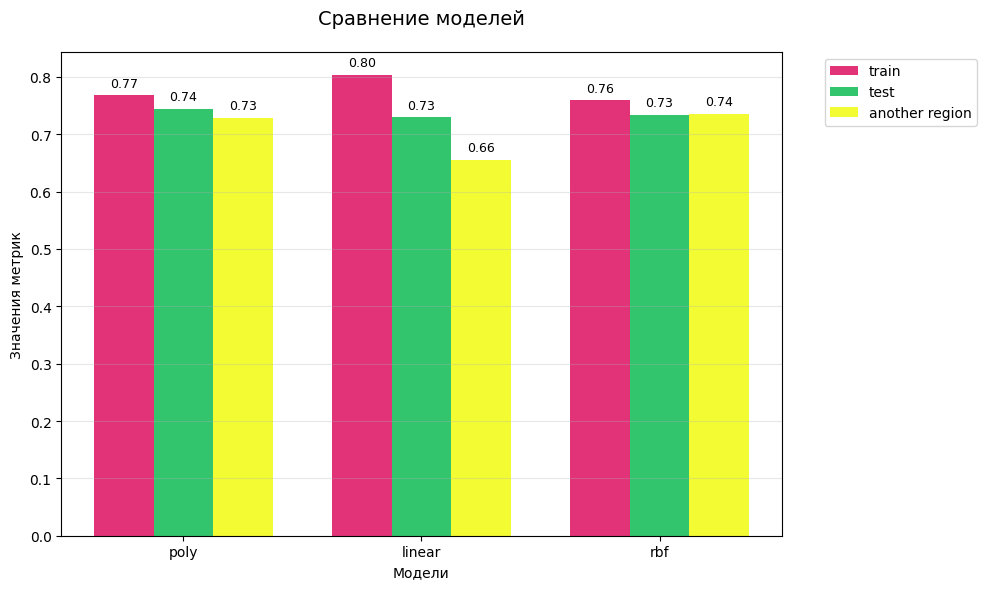

In [21]:
models = ['poly', 'linear', 'rbf']
metrics = ['train', 'test', 'another region']

data = np.array([
    poly_scores,
    linear_scores,
    rbf_scores,
])

fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.25
x_pos = np.arange(len(models))

colors = ['#DB0058', '#00B74A', '#F0FC00']
for i in range(len(metrics)):
    ax.bar(x_pos + i * bar_width, data[:, i], bar_width,
            label=metrics[i], color=colors[i], alpha=0.8)

ax.set_xlabel('Модели')
ax.set_ylabel('Значения метрик')
ax.set_title('Сравнение моделей', fontsize=14, pad=20)
ax.set_xticks(x_pos + bar_width)
ax.set_xticklabels(models)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

for i in range(len(models)):
    for j in range(len(metrics)):
        ax.text(i + j * bar_width, data[i, j] + 0.01,
                f'{data[i, j]:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

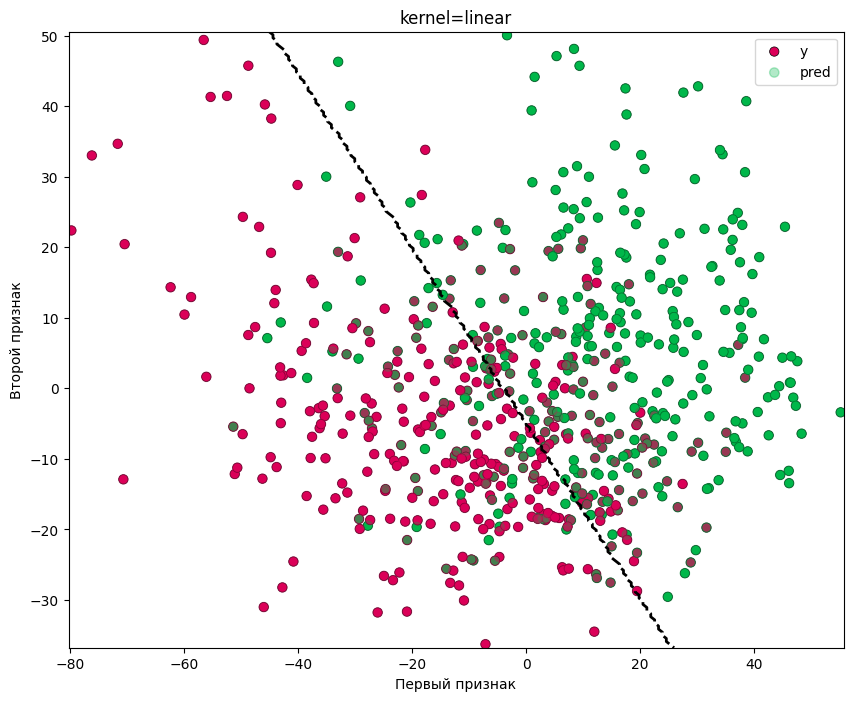

In [77]:
poly = PolynomialFeatures(
    degree=best_params_linear['degree'],
    interaction_only=bool(best_params_linear['interaction_only']),
    include_bias=bool(best_params_linear['include_bias'])
)

X_poly = poly.fit_transform(X)

pca = PCA(n_components=2, random_state=8)
X_transformed = pca.fit_transform(X_poly)

pred = model_lin.predict(X_poly)

fig, ax = plt.subplots(figsize=(10, 8))

colors_true = ['#DB0058' if label == -1 else '#00B74A' for label in y]
colors_pred = ['#DB0058' if label == -1 else '#00B74A' for label in pred]

scatter_true = ax.scatter(X_transformed[:, 0], X_transformed[:, 1], s=45, c=colors_true, label='y', edgecolors='black', linewidth=0.5)
scatter_pred = ax.scatter(X_transformed[:, 0], X_transformed[:, 1], alpha=0.3, c=colors_pred, label='pred', s=45)

x_min, x_max = X_transformed[:, 0].min() - 0.5, X_transformed[:, 0].max() + 0.5
y_min, y_max = X_transformed[:, 1].min() - 0.5, X_transformed[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

X_grid_pca = np.c_[xx.ravel(), yy.ravel()]
X_grid_poly = pca.inverse_transform(X_grid_pca)

Z = model_lin.predict(X_grid_poly)
Z = Z.reshape(xx.shape)

contour = ax.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black', linestyles='--')

plt.title('kernel=linear')
plt.xlabel('Первый признак')
plt.ylabel('Второй признак')
plt.legend()
plt.show()

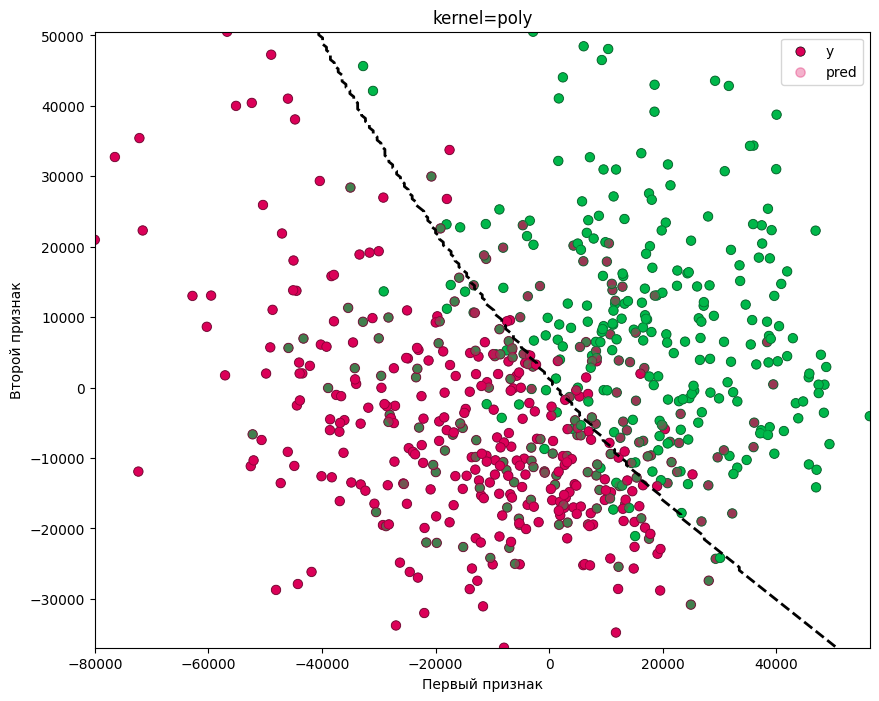

In [83]:
poly = PolynomialFeatures(
    degree=best_params_poly['degree'],
    interaction_only=bool(best_params_poly['interaction_only']),
    include_bias=bool(best_params_poly['include_bias'])
)

X_poly = poly.fit_transform(X)

pca = PCA(n_components=2, random_state=8)
X_transformed = pca.fit_transform(X_poly)

pred = model_poly.predict(X_poly)

fig, ax = plt.subplots(figsize=(10, 8))

colors_true = ['#DB0058' if label == -1 else '#00B74A' for label in y]
colors_pred = ['#DB0058' if label == -1 else '#00B74A' for label in pred]

scatter_true = ax.scatter(X_transformed[:, 0], X_transformed[:, 1], s=45, c=colors_true, label='y', edgecolors='black', linewidth=0.5)
scatter_pred = ax.scatter(X_transformed[:, 0], X_transformed[:, 1], alpha=0.3, c=colors_pred, label='pred', s=45)

x_min, x_max = X_transformed[:, 0].min() - 0.5, X_transformed[:, 0].max() + 0.5
y_min, y_max = X_transformed[:, 1].min() - 0.5, X_transformed[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

X_grid_pca = np.c_[xx.ravel(), yy.ravel()]
X_grid_poly = pca.inverse_transform(X_grid_pca)

Z = model_poly.predict(X_grid_poly)
Z = Z.reshape(xx.shape)

contour = ax.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black', linestyles='--')

plt.title('kernel=poly')
plt.xlabel('Первый признак')
plt.ylabel('Второй признак')
plt.legend()
plt.show()

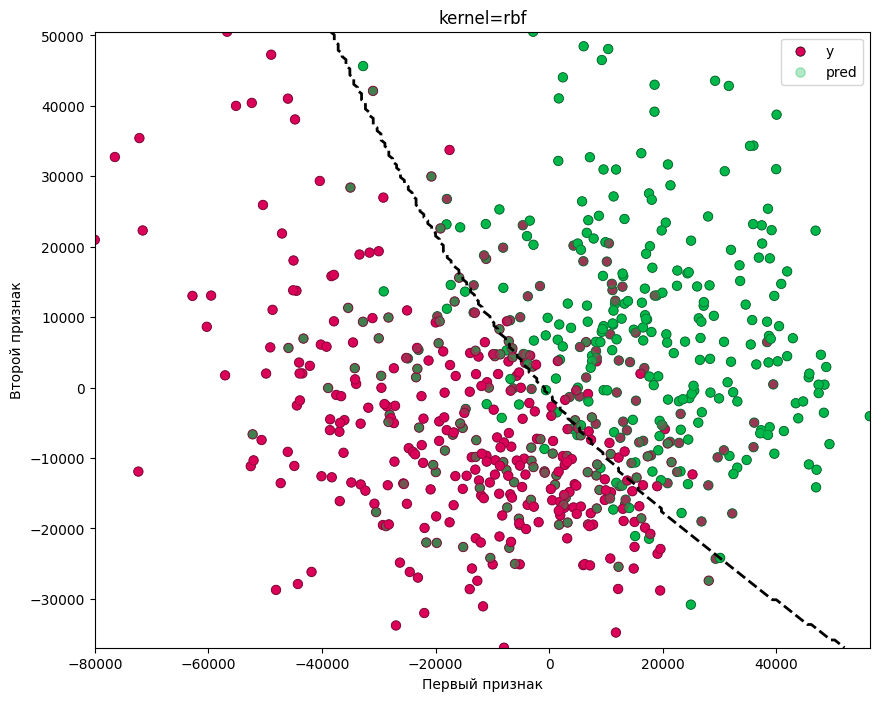

In [85]:
poly = PolynomialFeatures(
    degree=best_params_rbf['degree'],
    interaction_only=bool(best_params_rbf['interaction_only']),
    include_bias=bool(best_params_rbf['include_bias'])
)

X_poly = poly.fit_transform(X)

pca = PCA(n_components=2, random_state=8)
X_transformed = pca.fit_transform(X_poly)

pred = model_rbf.predict(X_poly)

fig, ax = plt.subplots(figsize=(10, 8))

colors_true = ['#DB0058' if label == -1 else '#00B74A' for label in y]
colors_pred = ['#DB0058' if label == -1 else '#00B74A' for label in pred]

scatter_true = ax.scatter(X_transformed[:, 0], X_transformed[:, 1], s=45, c=colors_true, label='y', edgecolors='black', linewidth=0.5)
scatter_pred = ax.scatter(X_transformed[:, 0], X_transformed[:, 1], alpha=0.3, c=colors_pred, label='pred', s=45)

x_min, x_max = X_transformed[:, 0].min() - 0.5, X_transformed[:, 0].max() + 0.5
y_min, y_max = X_transformed[:, 1].min() - 0.5, X_transformed[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

X_grid_pca = np.c_[xx.ravel(), yy.ravel()]
X_grid_poly = pca.inverse_transform(X_grid_pca)

Z = model_rbf.predict(X_grid_poly)
Z = Z.reshape(xx.shape)

contour = ax.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black', linestyles='--')

plt.title('kernel=rbf')
plt.xlabel('Первый признак')
plt.ylabel('Второй признак')
plt.legend()
plt.show()

## Сравнение результатов с бинарным классификатором

In [ ]:
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y, test_size=0.3, random_state=8
)

model = LogisticRegression(fit_intercept=False, max_iter=5000, random_state=8)
model.fit(Xtrain, ytrain)
model_scores = [model.score(Xtrain, ytrain), model.score(Xtest, ytest), model.score(newX, newy)]

In [ ]:
models = ['SVC_linear', 'binary']
metrics = ['train', 'test', 'another region']

data = np.array([
    linear_scores,
    model_scores
])

fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.25
x_pos = np.arange(len(models))

colors = ['#DB0058', '#00B74A', '#F0FC00']
for i in range(len(metrics)):
    ax.bar(x_pos + i * bar_width, data[:, i], bar_width,
            label=metrics[i], color=colors[i], alpha=0.8)

ax.set_xlabel('Модели')
ax.set_ylabel('Значения метрик')
ax.set_title('Сравнение моделей', fontsize=14, pad=20)
ax.set_xticks(x_pos + bar_width)
ax.set_xticklabels(models)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

for i in range(len(models)):
    for j in range(len(metrics)):
        ax.text(i + j * bar_width, data[i, j] + 0.01,
                f'{data[i, j]:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# model2 = LogisticRegression(fit_intercept=False, max_iter=3000, random_state=8)
# model2.fit(xtrain2, ytrain2)

In [ ]:
# models = ['SVC_linear', 'binary']
# metrics = ['train', 'test', 'another region']

# data = np.array([
#     [model_lin2.score(xtrain2, ytrain2), model_lin2.score(xtest2, ytest2), model_lin2.score(newX2, newy2)],
#     [model2.score(xtrain2, ytrain2), model2.score(xtest2, ytest2), model2.score(newX2, newy2)]
# ])

# fig, ax = plt.subplots(figsize=(10, 6))

# bar_width = 0.25
# x_pos = np.arange(len(models))

# colors = ['#DB0058', '#00B74A', '#F0FC00']
# for i in range(len(metrics)):
#     ax.bar(x_pos + i * bar_width, data[:, i], bar_width,
#             label=metrics[i], color=colors[i], alpha=0.8)

# ax.set_xlabel('Модели')
# ax.set_ylabel('Значения метрик')
# ax.set_title('Сравнение моделей обученных на грязных данных', fontsize=14, pad=20)
# ax.set_xticks(x_pos + bar_width)
# ax.set_xticklabels(models)
# ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
# ax.grid(axis='y', alpha=0.3)

# for i in range(len(models)):
#     for j in range(len(metrics)):
#         ax.text(i + j * bar_width, data[i, j] + 0.01,
#                 f'{data[i, j]:.2f}', ha='center', va='bottom', fontsize=9)

# plt.tight_layout()
# plt.show()

# Эксперименты
## обучу все модели на грязных данных

In [87]:
learn_df = df[df.remainder__Location == city1].drop(['cat__RainTomorrow_No', 'cat__RainToday_No'], axis=1)
y = learn_df['cat__RainTomorrow_Yes'].values
y[y == 0] = -1
X = learn_df.drop(['remainder__Location', 'cat__RainTomorrow_Yes'], axis=1).values

new_df = df[df.remainder__Location == city2].drop(['cat__RainTomorrow_No', 'cat__RainToday_No'], axis=1)
newy2 = new_df['cat__RainTomorrow_Yes'].values
newy2[newy2 == 0] = -1
newX2 = new_df.drop(['remainder__Location', 'cat__RainTomorrow_Yes'], axis=1).values

## Linear

In [90]:
poly = PolynomialFeatures(
    degree=best_params_linear['degree'],
    interaction_only=bool(best_params_linear['interaction_only']),
    include_bias=bool(best_params_linear['include_bias'])
)
scale = StandardScaler(with_mean=False, with_std=False)

X_poly2 = poly.fit_transform(newX2)
Xtrain2, Xtest2, ytrain2, ytest2 = train_test_split(
    X_poly2, newy2, test_size=0.3, random_state=8
)

Xtrain_scaled2 = scale.fit_transform(Xtrain2)
Xtest_scaled2 = scale.transform(Xtest2)
newX_scaled2 = scale.transform(poly.transform(newX2))

model_lin2 = SVC(kernel='linear', C=8)
model_lin2.fit(Xtrain_scaled2, ytrain2)
linear_scores2 = [model_lin2.score(Xtrain_scaled2, ytrain2), model_lin2.score(Xtest_scaled2, ytest2), model_lin2.score(newX_scaled2, newy2)]

## Poly

In [92]:
poly = PolynomialFeatures(
    degree=best_params_poly['degree'],
    interaction_only=bool(best_params_poly['interaction_only']),
    include_bias=bool(best_params_poly['include_bias'])
)
scale = StandardScaler(with_mean=False, with_std=False)

X_poly2 = poly.fit_transform(newX2)
Xtrain2, Xtest2, ytrain2, ytest2 = train_test_split(
    X_poly2, newy2, test_size=0.3, random_state=8
)

Xtrain_scaled2 = scale.fit_transform(Xtrain2)
Xtest_scaled2 = scale.transform(Xtest2)
newX_scaled2 = scale.transform(poly.transform(newX2))

model_poly2 = SVC(kernel='linear', C=8)
model_poly2.fit(Xtrain_scaled2, ytrain2)
poly_scores2 = [model_poly2.score(Xtrain_scaled2, ytrain2), model_poly2.score(Xtest_scaled2, ytest2), model_poly2.score(newX_scaled2, newy2)]

## Rbf

In [93]:
poly = PolynomialFeatures(
    degree=best_params_rbf['degree'],
    interaction_only=bool(best_params_rbf['interaction_only']),
    include_bias=bool(best_params_rbf['include_bias'])
)
scale = StandardScaler(with_mean=False, with_std=False)

X_poly2 = poly.fit_transform(newX2)
Xtrain2, Xtest2, ytrain2, ytest2 = train_test_split(
    X_poly2, newy2, test_size=0.3, random_state=8
)

Xtrain_scaled2 = scale.fit_transform(Xtrain2)
Xtest_scaled2 = scale.transform(Xtest2)
newX_scaled2 = scale.transform(poly.transform(newX2))

model_rbf2 = SVC(kernel='rbf', C=3)
model_rbf2.fit(Xtrain_scaled, ytrain)
rbf_scores2 = [model_rbf2.score(Xtrain_scaled, ytrain), model_rbf2.score(Xtest_scaled, ytest), model_rbf2.score(newX_scaled, newy)]

## Визуализация

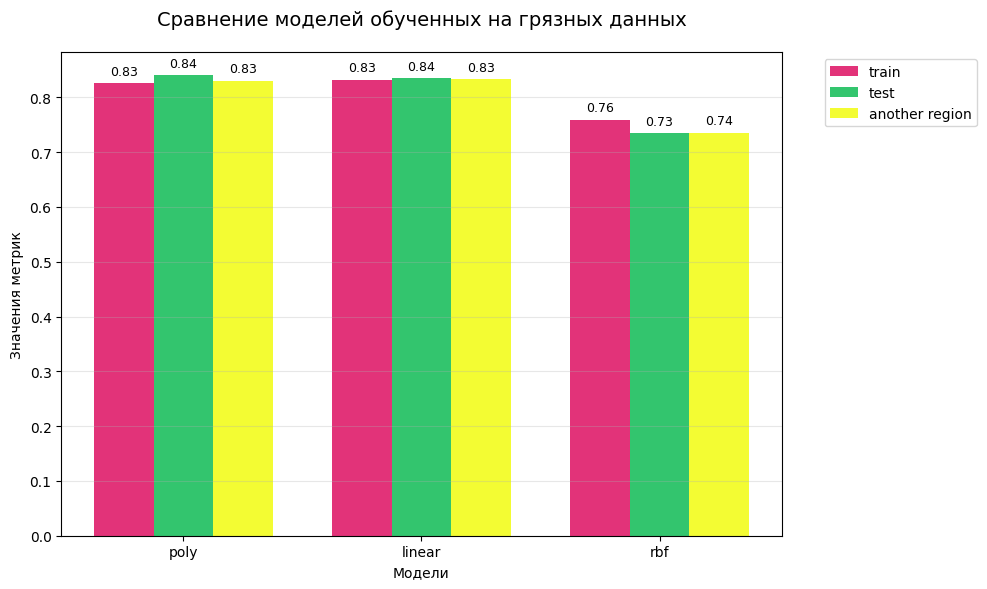

In [95]:
models = ['poly', 'linear', 'rbf']
metrics = ['train', 'test', 'another region']

data = np.array([
    poly_scores2,
    linear_scores2,
    rbf_scores2,
])

fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.25
x_pos = np.arange(len(models))

colors = ['#DB0058', '#00B74A', '#F0FC00']
for i in range(len(metrics)):
    ax.bar(x_pos + i * bar_width, data[:, i], bar_width,
            label=metrics[i], color=colors[i], alpha=0.8)

ax.set_xlabel('Модели')
ax.set_ylabel('Значения метрик')
ax.set_title('Сравнение моделей обученных на грязных данных', fontsize=14, pad=20)
ax.set_xticks(x_pos + bar_width)
ax.set_xticklabels(models)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

for i in range(len(models)):
    for j in range(len(metrics)):
        ax.text(i + j * bar_width, data[i, j] + 0.01,
                f'{data[i, j]:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Poly хорошо улучшил свой скор после увеличения числа признаков, а попытка улучшить результат за счет выравнивания данных была безуспешной, т.к из-за того, что данных стало сильно меньше, модель хуже обучилась (предположения). Комбинация стэндарт скейлера и полиноминал фичерс помогла добиться стабильного результата на всех трех измерениях.